# Information asymétrique : types privés, antisélection et mécanismes

> **Navigation.** Ce notebook prolonge [GameTheory-11 — jeux bayésiens](../GameTheory-11-BayesianGames-Python.ipynb), [GameTheory-16 — design de mécanismes](../GameTheory-16-MechanismDesign-Python.ipynb) et leur formalisation bayésienne. Il réutilise le cadre de Harsanyi sans dupliquer ses définitions.
>
> **Jumeau Python** → [GameTheory-17b-Asymmetric-Information-Python](GameTheory-17b-Asymmetric-Information-Python.ipynb) — le carnet d'origine, en Python.

## Objectifs d’apprentissage

À la fin de ce notebook, vous saurez :

1. déterminer comment un prix modifie endogènement la composition d’un marché à qualité privée ;
2. vérifier les contraintes IC/IR d’un signal séparateur et lire graphiquement le single-crossing ;
3. distinguer équilibre actuariel type par type, équilibre concurrentiel et déviation de cream-skimming ;
4. simuler une réaction anticipée avec retrait puis recalcul des choix ;
5. séparer les résultats analytiques des observations obtenues sur une grille finie.

**Prérequis :** espérance conditionnelle, équilibre de Nash, utilité espérée et jeux bayésiens.  
**Durée indicative :** 90 minutes, exercices compris.

## 1. Une même maladie, quatre réponses institutionnelles

L’**antisélection** vient d’une information privée détenue *avant* l’échange ou la signature : la qualité, la productivité ou le risque ne sont pas observés symétriquement. Elle se distingue de l’**aléa moral**, qui porte sur une action privée *après* contrat et reste hors du modèle principal.

La question commune est compositionnelle : **comment un prix, un signal ou un contrat change-t-il l’ensemble des participants qui se sélectionnent eux-mêmes ?** Le parcours suit quatre réponses de plus en plus riches :

- **Akerlof** diagnostique l’effondrement possible d’un pool sous prix unique ;
- **Spence** laisse l’agent informé agir par un signal coûteux ;
- **Rothschild–Stiglitz** fait proposer un menu par le côté non informé ;
- **Wilson / Miyazaki / Spence** évalue une entrée après la réaction anticipée des contrats incumbents.

## 2. Harsanyi — types et croyances

Dans un jeu bayésien fini, un type privé $\theta\in\Theta$ est tiré selon un prior commun. Une stratégie de l’agent informé est contingente à son type ; après une observation, les croyances sont mises à jour lorsque l’événement observé a une probabilité positive. Les lettres $H/L$ changent de sens selon le modèle : qualité haute/basse chez Akerlof, productivité haute/basse chez Spence, risque haut/bas en assurance.

## 3. Outils et notations communs

| Symbole | Objet | Rôle dans les modèles |
|---|---|---|
| $\theta\in\Theta=\{L,H\}$ | type privé | qualité, productivité ou risque selon la section |
| $a\in A$ | action | choix générique contingent au type |
| $s\in S$ | signal | décision coûteuse observée dans Spence |
| $(q,p)\in Q\times\mathbb R$ | contrat | couverture $q$ et prime $p$ en assurance |
| $u(a,\theta)$ | utilité | évalue l’action ou le contrat pour le type $\theta$ |
| $c(\theta,s)$ | coût du signal | transforme le salaire en utilité $w(s)-c(\theta,s)$ |
| IC / IR | incitation / participation | auto-sélection et préférence au contrat extérieur |

La propriété de **single-crossing** ordonne les préférences par différences croissantes. Si $\theta_H>\theta_L$ et $a'>a$ :

$$u(a',\theta_H)-u(a,\theta_H)\ge u(a',\theta_L)-u(a,\theta_L).$$

Dans un modèle $u=w-c$, la même idée devient un coût incrémental plus faible pour le type haut :

$$c(\theta_H,s')-c(\theta_H,s)\le c(\theta_L,s')-c(\theta_L,s),\qquad s'>s.$$

Cette propriété concerne les différences d’utilité ou de coût marginal ; elle ne doit pas être confondue avec un ratio de vraisemblance monotone. Akerlof reste ici **price-only** : aucun menu, signal ou single-crossing n’y est supposé.

## 4. Carte descriptive des modèles

| Modèle | Information privée | Instrument | Objet d’équilibre étudié ici |
|---|---|---|---|
| Akerlof (1970) | qualité du vendeur | prix unique | point fixe de participation |
| Spence (1973) | productivité du candidat | signal coûteux | paire séparatrice sous IC/IR |
| Rothschild–Stiglitz (1976) | probabilité de sinistre | contrats concurrents | Nash entre assureurs sur un domaine fini |
| Wilson / Miyazaki / Spence | risque privé | menu anticipatif fini | stabilité sous la règle de retrait codée |

> **Frontière de validité.** Les calculs RS et Wilson/MWS portent sur des domaines finis et une utilité CARA paramétrée. Ils rendent les mécanismes falsifiables, mais ne constituent ni une preuve d’existence ni une preuve d’unicité générale.

> **Ancres savantes.** Akerlof (1970), *The Quarterly Journal of Economics*, 84(3), 488–500 ; Spence (1973), *The Quarterly Journal of Economics*, 87(3), 355–374 ; Rothschild et Stiglitz (1976), *The Quarterly Journal of Economics*, 90(4), 629–649 ; Wilson (1977), *The Bell Journal of Economics*, 8(1), 167–207 ; Miyazaki (1977), *The Bell Journal of Economics*, 8(2), 394–418.

In [1]:
#nullable enable
using System;
using System.Collections.Generic;
using System.Globalization;
using System.Linq;
using System.Text;

// Les calculs utilisent double et les affichages une culture indépendante du système.
CultureInfo.CurrentCulture = CultureInfo.InvariantCulture;
CultureInfo.CurrentUICulture = CultureInfo.InvariantCulture;
const double tolerance = 1e-9;
var ecarts = new Dictionary<string, double>();
void VerifierProche(string section, double obtenu, double attendu, double tol = tolerance)
{
    double ecart = Math.Abs(obtenu - attendu);
    if (double.IsNaN(obtenu) || ecart > tol)
        throw new InvalidOperationException($"{section} : obtenu={obtenu:R}, attendu={attendu:R}, écart={ecart:R}");
    if (!ecarts.ContainsKey(section) || ecart > ecarts[section]) ecarts[section] = ecart;
}
void Verifier(string message, bool condition)
{
    if (!condition) throw new InvalidOperationException(message);
}
string Nombre(double x) => x.ToString("0.###", CultureInfo.InvariantCulture);
Console.WriteLine("Environnement prêt : BCL, arithmétique double et outils de menus finis chargés");

Environnement prêt : BCL, arithmétique double et outils de menus finis chargés


## Akerlof : un point fixe de participation à prix unique

> **Provenance des références numériques.** Dans tout le carnet, les valeurs attendues codées en dur pour contrôler les résultats sont des données citées du jumeau Python : elles ne sont pas recalculées ici. Les valeurs obtenues et imprimées par les cellules C# proviennent en revanche des calculs exécutés dans ce carnet ; les assertions les comparent aux références citées.

Le vendeur observe la qualité $q\in\{L,H\}$. À un prix candidat $P$, les vendeurs participants forment

$$S(P)=\{q\mid c_q\le P\}.$$

Lorsque cet ensemble est non vide, l’acheteur accepte si

$$P\le \mathbb E[v(q)\mid q\in S(P)].$$

Le prix doit donc être compatible simultanément avec la participation des vendeurs et la disposition à payer de l’acheteur. Pour faire participer les deux qualités, il faut $P\ge c_H$ et $P\le \pi v_H+(1-\pi)v_L$. Si $v_H>v_L$, le pooling devient donc possible lorsque

$$\pi\ge\pi_{min}=\frac{c_H-v_L}{v_H-v_L}.$$

Ce seuil vaut uniquement pour le modèle fini défini ici.

Seuil analytique : pi_min = 0,333


scenario | pi | regime | participants | price_lower | price_upper | upper_closed | conditional_value


faible part de H | 0,200000 | lemons_only | (L,) | 1.0 | 3.0 | True | 3.0


seuil exact | 0,333333 | lemons_only | (L,) | 1.0 | 3.0 | True | 3.0


seuil exact | 0,333333 | pooling | (L, H) | 5.0 | 5.0 | True | 5.0


forte part de H | 0,500000 | lemons_only | (L,) | 1.0 | 3.0 | True | 3.0


forte part de H | 0,500000 | pooling | (L, H) | 5.0 | 6.0 | True | 6.0


aucun échange | 0,500000 | no_trade | () | NaN | NaN | NaN | NaN


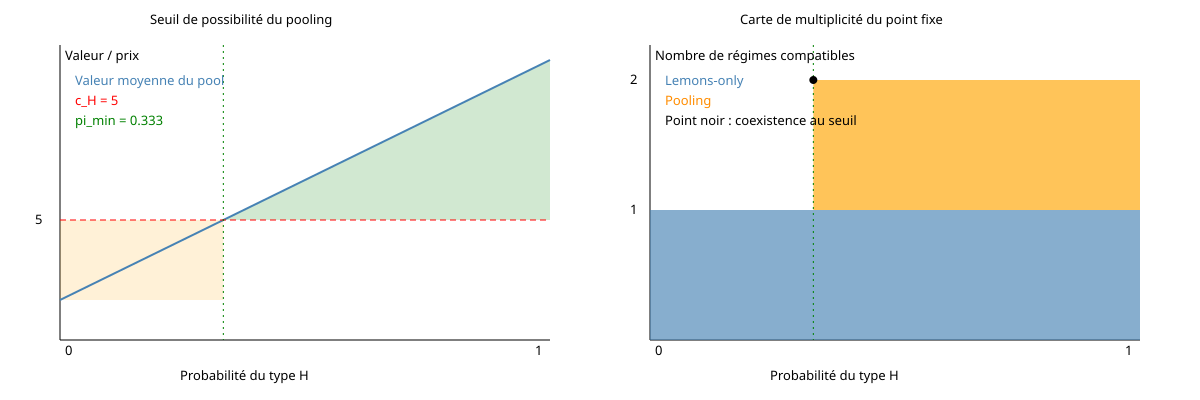

In [2]:
// Énumération des intervalles de prix compatibles avec la participation.
record AkerlofEquilibre(string Regime, string[] Participants, double? PriceLower, double? PriceUpper, bool? UpperClosed, double? ConditionalValue);
record ScenarioAkerlof(string Scenario, double Pi, double CLow, double CHigh, double VLow, double VHigh);
record LigneAkerlof(string Scenario, double Pi, AkerlofEquilibre Equilibre);
List<AkerlofEquilibre> AkerlofEquilibria(double pi, double cLow, double cHigh, double vLow, double vHigh)
{
    if (!(0 <= pi && pi <= 1)) throw new ArgumentOutOfRangeException(nameof(pi));
    if (!(cLow < cHigh)) throw new ArgumentException("Le modèle suppose c_low < c_high");
    if (!(vLow < vHigh)) throw new ArgumentException("Le modèle suppose v_low < v_high");
    var resultat = new List<AkerlofEquilibre>();
    double lemonsUpper = Math.Min(cHigh, vLow);
    if (cLow <= lemonsUpper)
        resultat.Add(new AkerlofEquilibre("lemons_only", new[] { "L" }, cLow, lemonsUpper, vLow < cHigh, vLow));
    double valeurPool = pi * vHigh + (1.0 - pi) * vLow;
    if (cHigh <= valeurPool)
        resultat.Add(new AkerlofEquilibre("pooling", new[] { "L", "H" }, cHigh, valeurPool, true, valeurPool));
    if (resultat.Count == 0)
        resultat.Add(new AkerlofEquilibre("no_trade", Array.Empty<string>(), null, null, null, null));
    return resultat;
}

// Les quatre scénarios et la grille sont ceux du carnet Python.
var scenarios = new[] {
    new ScenarioAkerlof("faible part de H", 0.20, 1, 5, 3, 9),
    new ScenarioAkerlof("seuil exact", 1.0 / 3.0, 1, 5, 3, 9),
    new ScenarioAkerlof("forte part de H", 0.50, 1, 5, 3, 9),
    new ScenarioAkerlof("aucun échange", 0.50, 4, 7, 3, 6)
};
var akerlof_results = scenarios.SelectMany(s => AkerlofEquilibria(s.Pi, s.CLow, s.CHigh, s.VLow, s.VHigh).Select(e => new LigneAkerlof(s.Scenario, s.Pi, e))).ToArray();
var pi_values = Enumerable.Range(0, 201).Select(i => i / 200.0).ToArray();
var pooling_values = pi_values.Select(p => p * 9 + (1 - p) * 3).ToArray();
double pi_min = (5.0 - 3.0) / (9.0 - 3.0);
var regime_map = pi_values.Select(p => {
    var eq = AkerlofEquilibria(p, 1, 5, 3, 9);
    return (Pi: p, Lemons: eq.Any(e => e.Regime == "lemons_only"), Pooling: eq.Any(e => e.Regime == "pooling"));
}).ToArray();

// Contrôles des valeurs et des régimes, y compris les bornes ouvertes.
var attendusRegimes = new[] { "lemons_only", "lemons_only", "pooling", "lemons_only", "pooling", "no_trade" };
var attendusBas = new double?[] { 1, 1, 5, 1, 5, null };
var attendusHaut = new double?[] { 3, 3, 5, 3, 6, null };
var attendusValeur = new double?[] { 3, 3, 5, 3, 6, null };
Verifier("Nombre de lignes Akerlof", akerlof_results.Length == attendusRegimes.Length);
for (int i = 0; i < akerlof_results.Length; i++)
{
    var e = akerlof_results[i].Equilibre;
    Verifier("Régime Akerlof", e.Regime == attendusRegimes[i]);
    Verifier("Participants Akerlof", string.Join(",", e.Participants) == (e.Regime == "pooling" ? "L,H" : e.Regime == "lemons_only" ? "L" : ""));
    Verifier("Présence des bornes", e.PriceLower.HasValue == attendusBas[i].HasValue && e.PriceUpper.HasValue == attendusHaut[i].HasValue && e.ConditionalValue.HasValue == attendusValeur[i].HasValue);
    if (attendusBas[i].HasValue)
    {
        VerifierProche("Akerlof", e.PriceLower!.Value, attendusBas[i]!.Value);
        VerifierProche("Akerlof", e.PriceUpper!.Value, attendusHaut[i]!.Value);
        VerifierProche("Akerlof", e.ConditionalValue!.Value, attendusValeur[i]!.Value);
        Verifier("Borne fermée", e.UpperClosed == true);
    }
    else Verifier("Absence de borne fermée", e.UpperClosed == null);
}
VerifierProche("Akerlof", pi_min, 1.0 / 3.0);
Verifier("Carte des régimes", regime_map.All(r => r.Lemons && r.Pooling == (r.Pi * 9 + (1 - r.Pi) * 3 >= 5)));

// Tableau utilisé pour la lecture et les exercices.
Console.WriteLine($"Seuil analytique : pi_min = {pi_min:F3}");
Console.WriteLine("scenario | pi | regime | participants | price_lower | price_upper | upper_closed | conditional_value");
foreach (var row in akerlof_results)
{
    var e = row.Equilibre;
    string participants = e.Participants.Length == 0 ? "()" : e.Participants.Length == 1 ? "(L,)" : "(L, H)";
    string FormatNullable(double? v) => v.HasValue ? v.Value.ToString("F1", CultureInfo.InvariantCulture) : "NaN";
    Console.WriteLine($"{row.Scenario} | {row.Pi:F6} | {e.Regime} | {participants} | {FormatNullable(e.PriceLower)} | {FormatNullable(e.PriceUpper)} | {(e.UpperClosed.HasValue ? (e.UpperClosed.Value ? "True" : "False") : "NaN")} | {FormatNullable(e.ConditionalValue)}");
}

// Deux panneaux SVG calculés depuis les mêmes tableaux que les résultats imprimés.
var svg = new StringBuilder();
svg.Append("<svg xmlns='http://www.w3.org/2000/svg' width='1200' height='400' viewBox='0 0 1200 400'><rect width='1200' height='400' fill='white'/><g font-family='sans-serif' font-size='13' fill='black'>");
svg.Append("<text x='150' y='24'>Seuil de possibilité du pooling</text><text x='740' y='24'>Carte de multiplicité du point fixe</text>");
svg.Append("<path d='M60 340 H550 M60 340 V45 M650 340 H1140 M650 340 V45' stroke='black' fill='none'/>");
string Points(IEnumerable<(double x, double y)> points) => string.Join(" ", points.Select(p => $"{Nombre(p.x)},{Nombre(p.y)}"));
double X1(double p) => 60 + 490 * p;
double Y1(double v) => 340 - (v - 2) * 40;
double X2(double p) => 650 + 490 * p;
double Y2(double n) => 340 - n * 130;
svg.Append($"<polygon points='{Points(new[] { (X1(0), Y1(3)), (X1(pi_min), Y1(3)), (X1(pi_min), Y1(5)), (X1(0), Y1(5)) })}' fill='orange' opacity='.16'/>");
svg.Append($"<polygon points='{Points(new[] { (X1(pi_min), Y1(5)), (X1(1), Y1(5)), (X1(1), Y1(9)) })}' fill='green' opacity='.18'/>");
svg.Append($"<polyline points='{Points(pi_values.Select((p, i) => (X1(p), Y1(pooling_values[i]))))}' fill='none' stroke='steelblue' stroke-width='2'/>");
svg.Append($"<line x1='{Nombre(X1(0))}' y1='{Nombre(Y1(5))}' x2='{Nombre(X1(1))}' y2='{Nombre(Y1(5))}' stroke='red' stroke-dasharray='6,4'/>");
svg.Append($"<line x1='{Nombre(X1(pi_min))}' y1='45' x2='{Nombre(X1(pi_min))}' y2='340' stroke='green' stroke-dasharray='2,4'/>");
svg.Append($"<polygon points='{Points(new[] { (X2(0), Y2(0)), (X2(1), Y2(0)), (X2(1), Y2(1)), (X2(0), Y2(1)) })}' fill='steelblue' opacity='.65'/>");
var poolPoints = new List<(double x, double y)> { (X2(pi_min), Y2(1)), (X2(1), Y2(1)), (X2(1), Y2(2)), (X2(pi_min), Y2(2)) };
svg.Append($"<polygon points='{Points(poolPoints)}' fill='orange' opacity='.65'/><line x1='{Nombre(X2(pi_min))}' y1='45' x2='{Nombre(X2(pi_min))}' y2='340' stroke='green' stroke-dasharray='2,4'/><circle cx='{Nombre(X2(pi_min))}' cy='{Nombre(Y2(2))}' r='4' fill='black'/>");
svg.Append("<text x='180' y='380'>Probabilité du type H</text><text x='770' y='380'>Probabilité du type H</text><text x='65' y='60'>Valeur / prix</text><text x='655' y='60'>Nombre de régimes compatibles</text><text x='65' y='355'>0</text><text x='535' y='355'>1</text><text x='655' y='355'>0</text><text x='1125' y='355'>1</text><text x='35' y='224'>5</text><text x='630' y='214'>1</text><text x='630' y='84'>2</text><text x='75' y='85' fill='steelblue'>Valeur moyenne du pool</text><text x='75' y='105' fill='red'>c_H = 5</text><text x='75' y='125' fill='green'>pi_min = 0.333</text><text x='665' y='85' fill='steelblue'>Lemons-only</text><text x='665' y='105' fill='darkorange'>Pooling</text><text x='665' y='125'>Point noir : coexistence au seuil</text></g></svg>");
// Une chaîne n'a pas de formateur SVG natif : enregistrer explicitement son rendu.
Microsoft.DotNet.Interactive.Formatting.Formatter.Register<string>((value, writer) => writer.Write(value), "image/svg+xml");
display(svg.ToString(), "image/svg+xml");

### Lecture du résultat

Le panneau gauche sépare deux propositions différentes. Sous $\pi_{min}=1/3$, la valeur moyenne du pool reste sous $c_H=5$ : aucun prix ne peut simultanément faire participer le type H et être accepté par l’acheteur. Au-dessus, un intervalle pooling devient **compatible**, mais « possible » ne veut pas dire « uniquement sélectionné ».

Le panneau droit rend cette nuance visible : `lemons_only` reste compatible sur toute la grille de $\pi$, tandis que `pooling` s’ajoute à partir du seuil. Au seuil exact, sa borne inférieure et sa borne supérieure coïncident en $P=c_H=5$ : c’est un équilibre singleton qui coexiste avec lemons-only. La multiplicité vient donc du point fixe de participation, pas d’une erreur de classification.

> **À retenir.** Akerlof décrit ici une maladie de composition : le prix modifie les qualités présentes, lesquelles modifient à leur tour la disposition à payer. Une condition de possibilité du pooling n’est pas un critère de sélection parmi plusieurs équilibres.

## Exercice 1 — classer les régimes

À partir du tableau précédent, compléter la fonction pour associer à chaque scénario l’ensemble de ses régimes. Vérifier en particulier que le scénario au seuil admet deux régimes, tandis que le dernier conduit à `no_trade`.

**Indice :** grouper les lignes par `scenario`, puis convertir la colonne `regime` en ensemble.

In [3]:
#nullable enable
// Illustration 1 — classer les régimes
Dictionary<string, HashSet<string>>? ExerciceClasserRegimes()
{
    // TODO étudiant : grouper akerlof_results par scénario et collecter les régimes.
    return null;
}
Console.WriteLine($"Classification à compléter : {ExerciceClasserRegimes()?.ToString() ?? "None"}");

Classification à compléter : None


## Exercice 2 — retrouver le seuil graphiquement

Compléter la fonction pour retourner le premier prior de la grille `pi_values` tel que la valeur du pooling atteint `c_high = 5`. Comparer ce résultat numérique à la formule analytique de $\pi_{min}$.

**Indice :** utiliser un masque booléen sur `pooling_values`, puis sélectionner son premier indice vrai.

In [4]:
// Illustration 2 — retrouver le seuil graphiquement
double? ExerciceSeuilNumerique()
{
    // TODO étudiant : trouver le premier pi tel que pooling_values >= 5.
    return null;
}
Console.WriteLine($"Seuil numérique à compléter : {ExerciceSeuilNumerique()?.ToString(CultureInfo.InvariantCulture) ?? "None"}");

Seuil numérique à compléter : None


## Exercice 3 — frontière d’Akerlof

Compléter la fonction suivante pour détecter si l’intervalle pooling se réduit à un prix unique au seuil $\pi_{min}$. Vérifier ensuite que `lemons_only` et `pooling` peuvent tous deux apparaître dans la liste retournée.

**Étape 1 :** appeler `AkerlofEquilibria` au seuil.  
**Étape 2 :** isoler le régime `pooling`.  
**Étape 3 :** comparer ses bornes inférieure et supérieure.

In [5]:
// Illustration 3 — frontière d’Akerlof
bool? ExercicePoolingSingleton()
{
    // TODO étudiant : appeler akerlof_equilibria au seuil et comparer les bornes.
    return null;
}
Console.WriteLine($"Résultat à compléter : {ExercicePoolingSingleton()?.ToString() ?? "None"}");

Résultat à compléter : None


## Spence : signal coûteux et contraintes d’incitation

Deux types de productivité $y_H>y_L$ choisissent un signal $s$. En séparation concurrentielle, $w(s_q)=y_q$ et l’utilité du candidat est

$$u(q,s)=w(s)-c(q,s).$$

Pour une paire séparatrice $(s_L,s_H)$, les quatre contraintes sont :

| Contrainte | Inégalité |
|---|---|
| $IC_H$ | $y_H-c(H,s_H)\ge y_L-c(H,s_L)$ |
| $IC_L$ | $y_L-c(L,s_L)\ge y_H-c(L,s_H)$ |
| $IR_H$ | $y_H-c(H,s_H)\ge \bar u_H$ |
| $IR_L$ | $y_L-c(L,s_L)\ge \bar u_L$ |

Avec $s_L=0$ et $c(q,s)=s/q$, les deux IC donnent

$$q_L(y_H-y_L)\le s_H\le q_H(y_H-y_L).$$

Les IR peuvent resserrer cet intervalle. Le séparateur de Riley est le plus petit $s_H$ qui dissuade le type bas tout en respectant la participation du type haut. Rien n’impose une rente informationnelle nulle.

Intervalle IC sans IR contraignante : [3,0, 6,0]


Vérification au séparateur de Riley :


contrainte | membre_gauche | membre_droit | respectee


IC_H | 3,5 | 2,0 | True


IC_L | 2,0 | 2,0 | True


IR_H | 3,5 | 0,0 | True


IR_L | 2,0 | 1,0 | True


option_exterieure_H | signal_low | signal_high_lower | signal_high_upper | riley_signal_high | intervalle


0,0 | 0,0 | 3,0 | 6,0 | 3,0 | NaN


3,0 | 0,0 | 3,0 | 4,0 | 3,0 | NaN


4,0 | NaN | NaN | NaN | NaN | vide


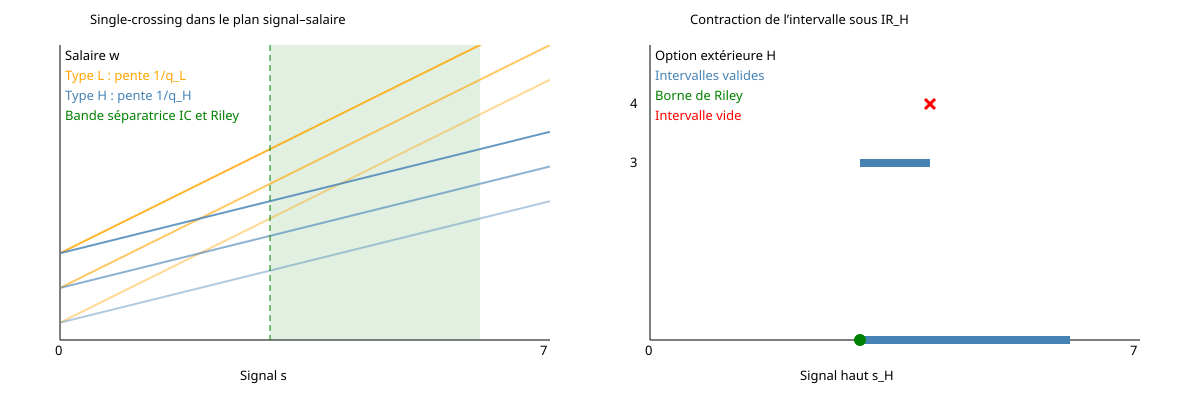

In [6]:
#nullable enable
// Intervalle séparateur avec coût s/q et signal bas nul.
record IntervalleSpence(double SignalLow, double SignalHighLower, double SignalHighUpper, double RileySignalHigh);
record LigneSpence(double OptionExterieureH, IntervalleSpence? Intervalle);
record ContrainteSpence(string Contrainte, double MembreGauche, double MembreDroit)
{
    public bool Respectee => MembreGauche >= MembreDroit - 1e-9;
}
IntervalleSpence? SpenceSeparatingInterval(double yLow, double yHigh, double qLow, double qHigh, double reserveLow = 0.0, double reserveHigh = 0.0)
{
    if (!(yLow < yHigh)) throw new ArgumentException("Le modèle suppose y_low < y_high");
    if (!(0.0 < qLow && qLow < qHigh)) throw new ArgumentException("Le modèle suppose 0 < q_low < q_high");
    if (yLow < reserveLow) return null;
    double gap = yHigh - yLow;
    double borneBasse = Math.Max(0.0, qLow * gap);
    double borneHaute = Math.Min(qHigh * gap, qHigh * (yHigh - reserveHigh));
    // Python math.isclose utilise par défaut une tolérance relative de 1e-9.
    bool proches = Math.Abs(borneBasse - borneHaute) <= 1e-9 * Math.Max(Math.Abs(borneBasse), Math.Abs(borneHaute));
    if (borneBasse > borneHaute && !proches) return null;
    return new IntervalleSpence(0.0, borneBasse, borneHaute, borneBasse);
}

// Les options extérieures et les contraintes reprennent les paramètres source.
var spence_results = new[] { 0.0, 3.0, 4.0 }
    .Select(r => new LigneSpence(r, SpenceSeparatingInterval(2, 5, 1, 2, 1, r))).ToArray();
var intervalleSpence = SpenceSeparatingInterval(2, 5, 1, 2, 1, 0)
    ?? throw new InvalidOperationException("Intervalle de référence vide");
double lower = intervalleSpence.SignalHighLower;
double upper = intervalleSpence.SignalHighUpper;
var signal_values = Enumerable.Range(0, 250).Select(i => 7.0 * i / 249.0).ToArray();
var ic_ir_at_riley = new[] {
    new ContrainteSpence("IC_H", 5 - lower / 2, 2 - 0.0 / 2),
    new ContrainteSpence("IC_L", 2 - 0.0 / 1, 5 - lower / 1),
    new ContrainteSpence("IR_H", 5 - lower / 2, 0),
    new ContrainteSpence("IR_L", 2 - 0.0 / 1, 1)
};

// Assertions sur les intervalles, les quatre contraintes et leurs membres.
Verifier("Nombre de cas Spence", spence_results.Length == 3);
Verifier("Les deux premiers intervalles existent", spence_results[0].Intervalle != null && spence_results[1].Intervalle != null);
Verifier("Le troisième intervalle est vide", spence_results[2].Intervalle == null);
var attenduHaut = new[] { 6.0, 4.0 };
for (int i = 0; i < 2; i++)
{
    var s = spence_results[i].Intervalle ?? throw new InvalidOperationException("Intervalle manquant");
    VerifierProche("Spence", s.SignalLow, 0);
    VerifierProche("Spence", s.SignalHighLower, 3);
    VerifierProche("Spence", s.SignalHighUpper, attenduHaut[i]);
    VerifierProche("Spence", s.RileySignalHigh, 3);
}
var attendusGauche = new[] { 3.5, 2.0, 3.5, 2.0 };
var attendusDroite = new[] { 2.0, 2.0, 0.0, 1.0 };
for (int i = 0; i < ic_ir_at_riley.Length; i++)
{
    VerifierProche("Spence", ic_ir_at_riley[i].MembreGauche, attendusGauche[i]);
    VerifierProche("Spence", ic_ir_at_riley[i].MembreDroit, attendusDroite[i]);
    Verifier("Contrainte IC/IR non respectée", ic_ir_at_riley[i].Respectee);
}

// Tables de résultats pour les deux panneaux et la lecture.
Console.WriteLine($"Intervalle IC sans IR contraignante : [{lower:F1}, {upper:F1}]");
Console.WriteLine("Vérification au séparateur de Riley :");
Console.WriteLine("contrainte | membre_gauche | membre_droit | respectee");
foreach (var c in ic_ir_at_riley)
    Console.WriteLine($"{c.Contrainte} | {c.MembreGauche:F1} | {c.MembreDroit:F1} | {(c.Respectee ? "True" : "False")}");
Console.WriteLine("option_exterieure_H | signal_low | signal_high_lower | signal_high_upper | riley_signal_high | intervalle");
foreach (var row in spence_results)
{
    var s = row.Intervalle;
    if (s == null) Console.WriteLine($"{row.OptionExterieureH:F1} | NaN | NaN | NaN | NaN | vide");
    else Console.WriteLine($"{row.OptionExterieureH:F1} | {s.SignalLow:F1} | {s.SignalHighLower:F1} | {s.SignalHighUpper:F1} | {s.RileySignalHigh:F1} | NaN");
}

// Les deux panneaux SVG sont construits à partir des tableaux calculés ci-dessus.
var svgSpence = new StringBuilder();
svgSpence.Append("<svg xmlns='http://www.w3.org/2000/svg' width='1200' height='400' viewBox='0 0 1200 400'><rect width='1200' height='400' fill='white'/><g font-family='sans-serif' font-size='13' fill='black'><defs><clipPath id='spence-clip'><rect x='60' y='45' width='490' height='295'/></clipPath></defs>");
svgSpence.Append("<text x='90' y='24'>Single-crossing dans le plan signal–salaire</text><text x='690' y='24'>Contraction de l’intervalle sous IR_H</text><path d='M60 340 H550 M60 340 V45 M650 340 H1140 M650 340 V45' stroke='black' fill='none'/>");
double SX(double s) => 60 + 490 * s / 7;
double SY(double w) => 340 - 295 * (w - 1.5) / 8.5;
double RX(double s) => 650 + 490 * s / 7;
double RY(double r) => 340 - 295 * r / 5;
string SVGPoints(IEnumerable<(double x, double y)> points) => string.Join(" ", points.Select(p => $"{Nombre(p.x)},{Nombre(p.y)}"));
svgSpence.Append($"<g clip-path='url(#spence-clip)'><rect x='{Nombre(SX(lower))}' y='45' width='{Nombre(SX(upper) - SX(lower))}' height='295' fill='green' opacity='.12'/>");
foreach (var niveau in new[] { (U: 2.0, Alpha: 0.42), (U: 3.0, Alpha: 0.62), (U: 4.0, Alpha: 0.82) })
{
    foreach (var type in new[] { (Q: 1.0, Couleur: "orange"), (Q: 2.0, Couleur: "steelblue") })
    {
        var pointsSpence = signal_values.Select(s => (SX(s), SY(niveau.U + s / type.Q)));
        svgSpence.Append($"<polyline points='{SVGPoints(pointsSpence)}' fill='none' stroke='{type.Couleur}' stroke-opacity='{Nombre(niveau.Alpha)}' stroke-width='2'/>");
    }
}
svgSpence.Append($"<line x1='{Nombre(SX(lower))}' x2='{Nombre(SX(lower))}' y1='45' y2='340' stroke='green' stroke-dasharray='6,4'/></g>");
foreach (var row in spence_results.Where(r => r.Intervalle != null))
{
    var s = row.Intervalle!;
    svgSpence.Append($"<line x1='{Nombre(RX(s.SignalHighLower))}' x2='{Nombre(RX(s.SignalHighUpper))}' y1='{Nombre(RY(row.OptionExterieureH))}' y2='{Nombre(RY(row.OptionExterieureH))}' stroke='steelblue' stroke-width='8'/>");
}
svgSpence.Append($"<circle cx='{Nombre(RX(lower))}' cy='{Nombre(RY(0))}' r='6' fill='green'/><path d='M{Nombre(RX(4)-5)} {Nombre(RY(4)-5)} l10 10 m0 -10 l-10 10' stroke='red' stroke-width='3'/>");
svgSpence.Append("<text x='240' y='380'>Signal s</text><text x='800' y='380'>Signal haut s_H</text><text x='65' y='60'>Salaire w</text><text x='655' y='60'>Option extérieure H</text><text x='65' y='80' fill='orange'>Type L : pente 1/q_L</text><text x='65' y='100' fill='steelblue'>Type H : pente 1/q_H</text><text x='65' y='120' fill='green'>Bande séparatrice IC et Riley</text><text x='655' y='80' fill='steelblue'>Intervalles valides</text><text x='655' y='100' fill='green'>Borne de Riley</text><text x='655' y='120' fill='red'>Intervalle vide</text><text x='55' y='355'>0</text><text x='540' y='355'>7</text><text x='645' y='355'>0</text><text x='1130' y='355'>7</text><text x='630' y='167'>3</text><text x='630' y='108'>4</text></g></svg>");
// Enregistrer le formateur SVG pour l'affichage de la chaîne.
Microsoft.DotNet.Interactive.Formatting.Formatter.Register<string>((value, writer) => writer.Write(value), "image/svg+xml");
display(svgSpence.ToString(), "image/svg+xml");

### Lecture du résultat

Le panneau gauche matérialise le single-crossing : pour conserver une même utilité lorsque le signal augmente, le salaire du type L doit croître deux fois plus vite que celui du type H. Cette différence de pentes ouvre la bande $[3,6]$ dans laquelle H accepte de se distinguer tandis que L refuse de l’imiter.

À la borne basse $s_H=3$, la table IC/IR confirme les quatre inégalités. Riley sélectionne cette borne parce qu’elle est le signal **le moins coûteux parmi ceux qui dissuadent L** ; cette sélection ne signifie pas que la rente de H est universellement nulle. Le panneau droit montre en outre que l’option extérieure de H resserre la borne supérieure : pour $\bar u_H=4$, IR_H rend l’intervalle vide.

> **Distinction utile.** Le single-crossing est ici une propriété des différences de coûts du signal. Une propriété de ratio de vraisemblance monotone porterait sur une famille de distributions observées ; elle n’est ni utilisée ni nécessaire dans ce calcul.

### Exercices 4 et 5 — Spence

**Exercice 4.** Compléter la fonction pour faire varier l’option extérieure du type haut et retourner les bornes de l’intervalle séparateur.  
**Indice :** appeler `SpenceSeparatingInterval` pour chaque valeur de `reserveHigh`.

**Exercice 5.** Vérifier numériquement les quatre contraintes IC/IR pour un signal haut candidat.  
**Indice :** calculer séparément les utilités des deux types sous vérité et imitation.

In [7]:
#nullable enable
// Illustration 4 — option extérieure ; illustration 5 — contraintes IC/IR
LigneSpence[]? ExerciceOptionExterieureSpence()
{
    // TODO étudiant : faire varier reserve_high et collecter les intervalles.
    return null;
}
Dictionary<string, bool>? ExerciceVerifierIcIr(double signalHigh)
{
    // TODO étudiant : évaluer séparément IC_H, IC_L, IR_H et IR_L.
    return null;
}
Console.WriteLine($"Exercices Spence à compléter : {ExerciceOptionExterieureSpence()?.ToString() ?? "None"} {ExerciceVerifierIcIr(3.0)?.ToString() ?? "None"}");

Exercices Spence à compléter : None None


## Rothschild–Stiglitz : screening concurrentiel fini

Un contrat $C=(\alpha,\beta)$ fixe une couverture $\alpha\in[0,1]$ et une prime $\beta$. La convention est explicite : $p_H>p_L$, donc `H` est le haut risque. Avec une perte $D$, le profit attendu de l’assureur pour un type $p$ est

$$\Pi(C,p)=\beta-p\alpha D.$$

La frontière actuariellement équitable est définie **type par type** par $\beta=p\alpha D$. Elle ne constitue pas une subvention croisée. Dans le concept de Rothschild–Stiglitz, un menu candidat est un Nash entre assureurs seulement si aucune déviation unilatérale n’attire un sous-ensemble de types avec profit conditionnel positif. La non-existence est donc conditionnelle à une déviation cream-skimming effectivement trouvée sur la grille finie.

Déviations profitables : 319 ; cream-skimming L seul : 176


Meilleure déviation L seul : couverture=0,90, prime=2,15, profit=1,430


couverture | prime | attire_L | attire_H | profit_conditionnel


0,15 | 0,15 | True | False | 0,03


0,15 | 0,20 | True | False | 0,08


0,15 | 0,25 | True | False | 0,13


... (3 outputs left out)

0,20 | 0,30 | True | False | 0,14


0,20 | 0,35 | True | False | 0,19


0,20 | 0,40 | True | False | 0,24


0,20 | 0,45 | True | False | 0,29


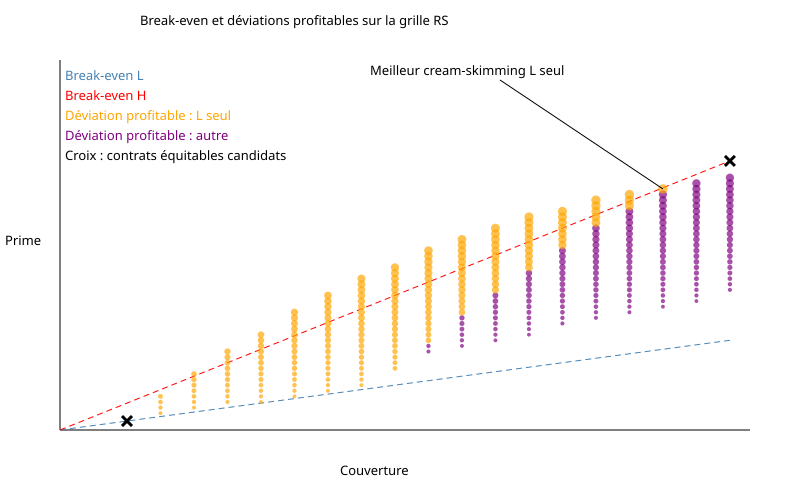

In [8]:
// Contrats et utilité CARA en arithmétique double.
record Contract(double Coverage, double Premium);
record MenuOutcome(Contract LowChoice, Contract HighChoice, double LowProfit, double HighProfit, double AggregateProfit, bool CrossSubsidy);
record DeviationRs(Contract Contract, bool AttractsLow, bool AttractsHigh, double ConditionalProfit);
double ExpectedUtility(Contract c, double p, double wealth = 10.0, double loss = 8.0, double riskAversion = 0.35)
{
    if (!(0 <= p && p <= 1)) throw new ArgumentOutOfRangeException(nameof(p));
    if (!(0 <= c.Coverage && c.Coverage <= 1)) throw new ArgumentOutOfRangeException(nameof(c));
    double sansSinistre = wealth - c.Premium;
    double avecSinistre = wealth - c.Premium - (1 - c.Coverage) * loss;
    return (1 - p) * -Math.Exp(-riskAversion * sansSinistre) + p * -Math.Exp(-riskAversion * avecSinistre);
}
double ExpectedProfit(Contract c, double p, double loss = 8.0) => c.Premium - p * c.Coverage * loss;
Contract ChosenContract(IEnumerable<Contract> menu, double p)
{
    // En cas d'égalité, conserver le premier contrat, comme max en Python.
    Contract meilleur = new Contract(0, 0);
    double utilite = ExpectedUtility(meilleur, p);
    foreach (var c in menu)
    {
        double u = ExpectedUtility(c, p);
        if (u > utilite) { meilleur = c; utilite = u; }
    }
    return meilleur;
}
MenuOutcome EvaluerMenu(Contract[] menu, double piHigh, double pLow, double pHigh)
{
    if (!(0 <= piHigh && piHigh <= 1)) throw new ArgumentOutOfRangeException(nameof(piHigh));
    if (!(0 < pLow && pLow < pHigh && pHigh < 1)) throw new ArgumentException("Le modèle suppose 0 < p_low < p_high < 1");
    var low = ChosenContract(menu, pLow);
    var high = ChosenContract(menu, pHigh);
    double profitLow = ExpectedProfit(low, pLow), profitHigh = ExpectedProfit(high, pHigh);
    return new MenuOutcome(low, high, profitLow, profitHigh, (1 - piHigh) * profitLow + piHigh * profitHigh, profitLow * profitHigh < 0);
}
List<DeviationRs> RsProfitableDeviations(Contract[] menu, Contract[] candidats, double piHigh, double pLow, double pHigh, double tol = 1e-9)
{
    var resultat = new List<DeviationRs>();
    var actuel = EvaluerMenu(menu, piHigh, pLow, pHigh);
    double uLow = ExpectedUtility(actuel.LowChoice, pLow), uHigh = ExpectedUtility(actuel.HighChoice, pHigh);
    foreach (var c in candidats)
    {
        bool attireLow = ExpectedUtility(c, pLow) > uLow + tol;
        bool attireHigh = ExpectedUtility(c, pHigh) > uHigh + tol;
        double masse = (1 - piHigh) * (attireLow ? 1 : 0) + piHigh * (attireHigh ? 1 : 0);
        if (masse <= 0) continue;
        double profit = ((1 - piHigh) * (attireLow ? 1 : 0) * ExpectedProfit(c, pLow) + piHigh * (attireHigh ? 1 : 0) * ExpectedProfit(c, pHigh)) / masse;
        if (profit > tol) resultat.Add(new DeviationRs(c, attireLow, attireHigh, profit));
    }
    return resultat;
}

// Grille source : 20 couvertures et 64 primes, bornes incluses.
double p_low = 0.10, p_high = 0.30, pi_high = 0.25;
var fair_low = new Contract(0.10, p_low * 0.10 * 8.0);
var fair_high = new Contract(1.00, p_high * 1.00 * 8.0);
VerifierProche("RS", ExpectedProfit(fair_low, p_low), 0);
VerifierProche("RS", ExpectedProfit(fair_high, p_high), 0);
var contract_grid = (from i in Enumerable.Range(0, 20)
                     from j in Enumerable.Range(0, 64)
                     select new Contract(i == 19 ? 1.0 : 0.05 + i * (0.95 / 19), j == 63 ? 3.20 : 0.05 + j * (3.15 / 63))).ToArray();
var deviations = RsProfitableDeviations(new[] { fair_low, fair_high }, contract_grid, pi_high, p_low, p_high);
var deviation_frame = deviations.ToArray();
var low_only = deviations.Where(d => d.AttractsLow && !d.AttractsHigh).ToArray();
Verifier("Déviations RS", deviations.Count == 319 && low_only.Length == 176);
var best_low_only = low_only.OrderByDescending(d => d.ConditionalProfit).First();
VerifierProche("RS", best_low_only.Contract.Coverage, 0.90);
VerifierProche("RS", best_low_only.Contract.Premium, 2.15);
VerifierProche("RS", best_low_only.ConditionalProfit, 1.43);
var rsHeadExpected = new[] { (0.15, 0.15, 0.03), (0.15, 0.20, 0.08), (0.15, 0.25, 0.13), (0.15, 0.30, 0.18), (0.20, 0.20, 0.04), (0.20, 0.25, 0.09), (0.20, 0.30, 0.14), (0.20, 0.35, 0.19), (0.20, 0.40, 0.24), (0.20, 0.45, 0.29) };
for (int i = 0; i < rsHeadExpected.Length; i++)
{
    var d = deviation_frame[i];
    VerifierProche("RS", d.Contract.Coverage, rsHeadExpected[i].Item1);
    VerifierProche("RS", d.Contract.Premium, rsHeadExpected[i].Item2);
    VerifierProche("RS", d.ConditionalProfit, rsHeadExpected[i].Item3);
    Verifier("Cible RS", d.AttractsLow && !d.AttractsHigh);
}
Console.WriteLine($"Déviations profitables : {deviations.Count} ; cream-skimming L seul : {low_only.Length}");
Console.WriteLine($"Meilleure déviation L seul : couverture={best_low_only.Contract.Coverage:F2}, prime={best_low_only.Contract.Premium:F2}, profit={best_low_only.ConditionalProfit:F3}");
Console.WriteLine("couverture | prime | attire_L | attire_H | profit_conditionnel");
foreach (var d in deviation_frame.Take(10))
    Console.WriteLine($"{d.Contract.Coverage:F2} | {d.Contract.Premium:F2} | {d.AttractsLow} | {d.AttractsHigh} | {d.ConditionalProfit:F2}");

// Nuage et frontières actuariellement équitables issus des données calculées.
var svgRs = new StringBuilder();
double RsX(double x) => 60 + 690 * x / 1.03;
double RsY(double y) => 430 - 370 * y / 3.3;
svgRs.Append("<svg xmlns='http://www.w3.org/2000/svg' width='800' height='500' viewBox='0 0 800 500'><rect width='800' height='500' fill='white'/><g font-family='sans-serif' font-size='13'><text x='140' y='25'>Break-even et déviations profitables sur la grille RS</text><path d='M60 430 H750 M60 430 V60' stroke='black' fill='none'/>");
foreach (var front in new[] { (P: p_low, Couleur: "steelblue"), (P: p_high, Couleur: "red") })
    svgRs.Append($"<line x1='{Nombre(RsX(0))}' y1='{Nombre(RsY(0))}' x2='{Nombre(RsX(1))}' y2='{Nombre(RsY(front.P * 8))}' stroke='{front.Couleur}' stroke-dasharray='6,4'/>");
foreach (var d in deviation_frame)
{
    string couleur = d.AttractsLow && !d.AttractsHigh ? "orange" : "purple";
    double rayon = Math.Sqrt((45 + 160 * d.ConditionalProfit) / Math.PI) / 2;
    svgRs.Append($"<circle cx='{Nombre(RsX(d.Contract.Coverage))}' cy='{Nombre(RsY(d.Contract.Premium))}' r='{Nombre(rayon)}' fill='{couleur}' opacity='.68'/>");
}
foreach (var c in new[] { fair_low, fair_high })
    svgRs.Append($"<path d='M{Nombre(RsX(c.Coverage)-5)} {Nombre(RsY(c.Premium)-5)} l10 10 m0 -10 l-10 10' stroke='black' stroke-width='3'/>");
svgRs.Append($"<text x='370' y='75'>Meilleur cream-skimming L seul</text><line x1='500' y1='80' x2='{Nombre(RsX(best_low_only.Contract.Coverage))}' y2='{Nombre(RsY(best_low_only.Contract.Premium))}' stroke='black'/>");
svgRs.Append("<text x='340' y='475'>Couverture</text><text x='5' y='245'>Prime</text><text x='65' y='80' fill='steelblue'>Break-even L</text><text x='65' y='100' fill='red'>Break-even H</text><text x='65' y='120' fill='orange'>Déviation profitable : L seul</text><text x='65' y='140' fill='purple'>Déviation profitable : autre</text><text x='65' y='160'>Croix : contrats équitables candidats</text></g></svg>");
// Enregistrer le formateur SVG pour l'affichage de la chaîne.
Microsoft.DotNet.Interactive.Formatting.Formatter.Register<string>((value, writer) => writer.Write(value), "image/svg+xml");
display(svgRs.ToString(), "image/svg+xml");

### Lecture du résultat

Les deux lignes pointillées sont des contraintes comptables distinctes : la pente du break-even H est plus forte parce que $p_H=0{,}30>p_L=0{,}10$. Les croix noires sont donc équitables **pour leur type respectif**, mais le profit nul type par type ne suffit pas à former un équilibre de Nash entre assureurs.

La cellule imprime le nombre total de déviations rentables et le sous-ensemble qui attire uniquement L. Le nuage montre où elles se situent dans l’espace couverture–prime ; la taille des points encode le profit conditionnel et l’annotation isole la meilleure déviation L-only de la grille. Ce contrat retire les bas risques du menu candidat : c’est le cream-skimming.

Le verdict est volontairement borné. Nous avons exhibé une déviation profitable pour cette grille, cette utilité CARA et ces paramètres ; nous n’avons pas démontré un théorème de non-existence sur le continuum des contrats. Le raisonnement complet distingue successivement **break-even**, **préférences des types**, **profit de la déviation**, puis **verdict d’équilibre**.

### Exercices 6 et 7 — Rothschild–Stiglitz

**Exercice 6.** Construire la frontière actuariellement équitable pour chaque type et vérifier le profit nul type par type.  
**Exercice 7.** Filtrer `deviation_frame` pour isoler les déviations qui attirent uniquement `L`, puis classer les cinq plus profitables.

Les deux exercices gardent distincts le break-even RS et une éventuelle subvention croisée au niveau d’un menu anticipatif.

In [9]:
#nullable enable
// Illustration 6 — frontières équitables ; illustration 7 — cream-skimming
record FrontiereEquitable(double Couverture, double PrimeLow, double PrimeHigh);
FrontiereEquitable[]? ExerciceFrontieresEquitables()
{
    // TODO étudiant : générer les primes break-even pour p_low et p_high.
    return null;
}
DeviationRs[]? ExerciceCreamSkimming()
{
    // TODO étudiant : filtrer puis trier les déviations qui attirent L seul.
    return null;
}
Console.WriteLine($"Exercices RS à compléter : {ExerciceFrontieresEquitables()?.ToString() ?? "None"} {ExerciceCreamSkimming()?.ToString() ?? "None"}");

Exercices RS à compléter : None None


## Wilson / Miyazaki / Spence : règle anticipative bornée

Nous fixons maintenant une définition computationnelle complète, sans lui attribuer une portée générale :

1. l’ensemble admissible est une grille finie de contrats ;
2. chaque type choisit son utilité CARA maximale, option extérieure comprise ;
3. le profit d’un menu est la moyenne pondérée des profits sur les contrats choisis ;
4. après l’entrée d’un nouveau contrat, tout contrat **incumbent choisi mais déficitaire** est retiré ;
5. les choix sont recalculés jusqu’au point fixe de retrait ;
6. une déviation est profitable si le profit final de l’entrant est positif ;
7. un menu est retenu s’il est faisable en profit agrégé et n’admet aucune telle déviation sur la grille.

Une subvention croisée est possible au niveau du menu lorsqu’un type génère un profit positif et l’autre un profit négatif, avec profit agrégé non négatif. L’énumération peut produire zéro, un ou plusieurs menus ; aucun résultat d’existence ou d’unicité n’est supposé.

Menus anticipatifs retenus : 9 sur une grille finie de 12 contrats


Exemple avant/après : 2 retrait(s), profit final entrant=1,000


tour | contrats_offerts | choix_L | choix_H | retraits


0 | 3 | (0.75, 0.4) | (0.75, 0.4) | [(0.75, 0.4)]


1 | 2 | (0.5, 0.4) | (0.5, 0.4) | [(0.5, 0.4)]


2 | 1 | (0.5, 1.6) | (0.5, 1.6) | []


... (6 outputs left out)

[(0.5, 0.8), (0.75, 1.2)] | (0.75, 1.2) | (0.75, 1.2) | 0,300 | True


[(0.5, 1.2), (0.75, 1.2)] | (0.75, 1.2) | (0.75, 1.2) | 0,300 | True


[(0.5, 1.6), (0.75, 1.2)] | (0.75, 1.2) | (0.75, 1.2) | 0,300 | True


[(0.75, 1.2), (0.75, 1.6)] | (0.75, 1.2) | (0.75, 1.2) | 0,300 | True


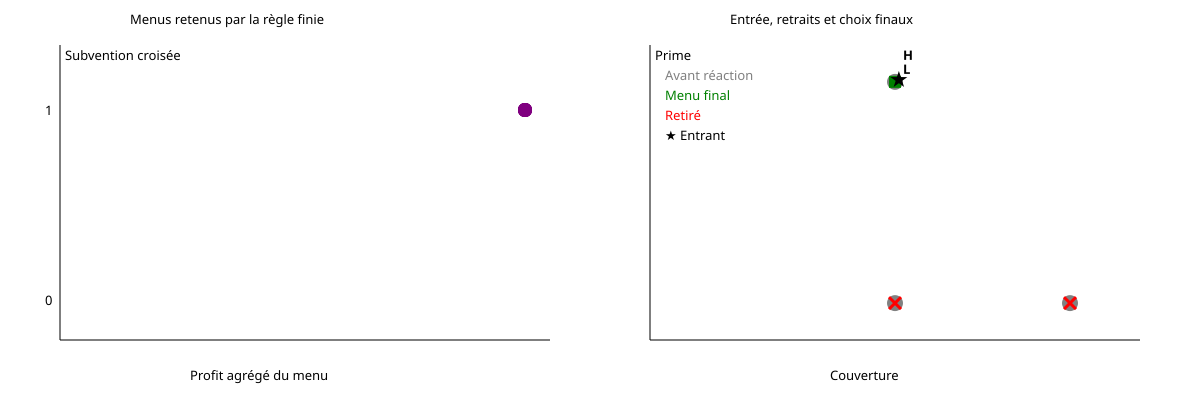

In [10]:
// Une réaction conserve la trace des choix et retraits successifs.
record EtapeRetrait(int Tour, Contract[] MenuActif, Contract[] Choix, Contract[] Retraits);
record ReactionAnticipative(Contract Entrant, Contract[] InitialMenu, Contract[] InitialChoices, Contract[] Withdrawn, Contract[] FinalMenu, Contract[] FinalChoices, EtapeRetrait[] Trace, double EntrantProfit, bool Profitable);
record MenuAnticipatif(Contract[] Menu, MenuOutcome Outcome, ReactionAnticipative[] Reactions);
ReactionAnticipative AnticipatoryDeviation(Contract[] incumbentMenu, Contract entrant, double piHigh, double pLow, double pHigh, double tol = 1e-9)
{
    var actifs = incumbentMenu.ToList();
    var retraits = new List<Contract>();
    var trace = new List<EtapeRetrait>();
    var initial = actifs.Append(entrant).ToArray();
    var choixInitiaux = new[] { ChosenContract(initial, pLow), ChosenContract(initial, pHigh) };
    Contract[] choix;
    while (true)
    {
        var disponibles = actifs.Append(entrant).ToArray();
        choix = new[] { ChosenContract(disponibles, pLow), ChosenContract(disponibles, pHigh) };
        var nouveaux = new List<Contract>();
        foreach (var c in actifs)
        {
            double profit = (choix[0] == c ? (1 - piHigh) * ExpectedProfit(c, pLow) : 0)
                          + (choix[1] == c ? piHigh * ExpectedProfit(c, pHigh) : 0);
            if (choix.Contains(c) && profit < -tol) nouveaux.Add(c);
        }
        trace.Add(new EtapeRetrait(trace.Count, disponibles, choix, nouveaux.ToArray()));
        if (nouveaux.Count == 0) break;
        retraits.AddRange(nouveaux);
        actifs.RemoveAll(c => nouveaux.Contains(c));
    }
    var final = actifs.Append(entrant).ToArray();
    var choixFinaux = new[] { ChosenContract(final, pLow), ChosenContract(final, pHigh) };
    double profitEntrant = (choixFinaux[0] == entrant ? (1 - piHigh) * ExpectedProfit(entrant, pLow) : 0)
                         + (choixFinaux[1] == entrant ? piHigh * ExpectedProfit(entrant, pHigh) : 0);
    return new ReactionAnticipative(entrant, initial, choixInitiaux, retraits.ToArray(), final, choixFinaux, trace.ToArray(), profitEntrant, profitEntrant > tol);
}
IEnumerable<Contract[]> CombinaisonsMenus(Contract[] contrats, int tailleMax)
{
    // La source utilise des menus de taille un ou deux dans l'ordre lexicographique.
    if (tailleMax >= 1)
        for (int i = 0; i < contrats.Length; i++) yield return new[] { contrats[i] };
    if (tailleMax >= 2)
        for (int i = 0; i < contrats.Length; i++)
            for (int j = i + 1; j < contrats.Length; j++) yield return new[] { contrats[i], contrats[j] };
}
List<MenuAnticipatif> AnticipatoryMenus(Contract[] contrats, double piHigh, double pLow, double pHigh, int tailleMax = 2, double tol = 1e-9)
{
    var retenus = new List<MenuAnticipatif>();
    foreach (var menu in CombinaisonsMenus(contrats, tailleMax))
    {
        var outcome = EvaluerMenu(menu, piHigh, pLow, pHigh);
        if (outcome.AggregateProfit < -tol) continue;
        var reactions = contrats.Where(c => !menu.Contains(c)).Select(c => AnticipatoryDeviation(menu, c, piHigh, pLow, pHigh, tol)).ToArray();
        if (!reactions.Any(r => r.Profitable)) retenus.Add(new MenuAnticipatif(menu, outcome, reactions));
    }
    return retenus;
}

// Grille finie, menus retenus et recherche de l'exemple à retraits multiples.
var small_grid = (from couverture in new[] { 0.25, 0.50, 0.75 }
                  from prime in new[] { 0.4, 0.8, 1.2, 1.6 }
                  select new Contract(couverture, prime)).ToArray();
var menus = AnticipatoryMenus(small_grid, pi_high, p_low, p_high);
var reaction_pool = (from menu in CombinaisonsMenus(small_grid, 2)
                     where menu.Length == 2
                     from entrant in small_grid
                     where !menu.Contains(entrant)
                     select AnticipatoryDeviation(menu, entrant, pi_high, p_low, p_high)).ToArray();
var withdrawal_examples = reaction_pool.Where(r => r.Withdrawn.Length > 0).ToArray();
var example_reaction = (withdrawal_examples.Length > 0 ? withdrawal_examples : reaction_pool)
    .OrderByDescending(r => r.Withdrawn.Length).ThenByDescending(r => r.EntrantProfit).First();

// Vérifications des valeurs citées dans la sortie Python et de la trace.
Verifier("Nombre de menus anticipatifs", menus.Count == 9 && small_grid.Length == 12);
Verifier("Nombre de retraits", example_reaction.Withdrawn.Length == 2 && example_reaction.Trace.Length == 3);
VerifierProche("Wilson", example_reaction.EntrantProfit, 1.0);
var choixAttendus = new[] { new Contract(0.75, 0.4), new Contract(0.5, 0.4), new Contract(0.5, 1.6) };
for (int i = 0; i < example_reaction.Trace.Length; i++)
{
    var etape = example_reaction.Trace[i];
    Verifier("Choix de la trace", etape.Choix[0] == choixAttendus[i] && etape.Choix[1] == choixAttendus[i]);
    Verifier("Retraits de la trace", etape.Retraits.Length == (i < 2 ? 1 : 0));
    if (i < 2) Verifier("Contrat retiré", etape.Retraits[0] == choixAttendus[i]);
}
string TexteContrat(Contract c) => $"({c.Coverage.ToString("0.0##", CultureInfo.InvariantCulture)}, {c.Premium.ToString("0.0##", CultureInfo.InvariantCulture)})";
string TexteMenu(IEnumerable<Contract> cs) => "[" + string.Join(", ", cs.Select(TexteContrat)) + "]";
Console.WriteLine($"Menus anticipatifs retenus : {menus.Count} sur une grille finie de {small_grid.Length} contrats");
Console.WriteLine($"Exemple avant/après : {example_reaction.Withdrawn.Length} retrait(s), profit final entrant={example_reaction.EntrantProfit:F3}");
Console.WriteLine("tour | contrats_offerts | choix_L | choix_H | retraits");
foreach (var etape in example_reaction.Trace)
    Console.WriteLine($"{etape.Tour} | {etape.MenuActif.Length} | {TexteContrat(etape.Choix[0])} | {TexteContrat(etape.Choix[1])} | {TexteMenu(etape.Retraits)}");
Console.WriteLine("menu | choix_L | choix_H | profit_agrege | subvention_croisee");
foreach (var m in menus.Take(10))
    Console.WriteLine($"{TexteMenu(m.Menu)} | {TexteContrat(m.Outcome.LowChoice)} | {TexteContrat(m.Outcome.HighChoice)} | {m.Outcome.AggregateProfit:F3} | {m.Outcome.CrossSubsidy}");

// Restitution des menus retenus et du cas avant/après en deux panneaux SVG.
var svgWilson = new StringBuilder();
svgWilson.Append("<svg xmlns='http://www.w3.org/2000/svg' width='1200' height='400' viewBox='0 0 1200 400'><rect width='1200' height='400' fill='white'/><g font-family='sans-serif' font-size='13'><text x='130' y='24'>Menus retenus par la règle finie</text><text x='730' y='24'>Entrée, retraits et choix finaux</text><path d='M60 340 H550 M60 340 V45 M650 340 H1140 M650 340 V45' stroke='black' fill='none'/>");
double maxProfitMenu = Math.Max(0.1, menus.Max(m => m.Outcome.AggregateProfit));
double MenuX(double p) => 75 + 450 * p / maxProfitMenu;
double MenuY(bool subvention) => subvention ? 110 : 300;
double ContratX(double c) => 650 + 490 * (c - 0.15) / 0.70;
double ContratY(double p) => 340 - 295 * (p - 0.2) / 1.6;
foreach (var m in menus)
    svgWilson.Append($"<circle cx='{Nombre(MenuX(m.Outcome.AggregateProfit))}' cy='{Nombre(MenuY(m.Outcome.CrossSubsidy))}' r='7' fill='purple' opacity='.75'/>");
foreach (var c in example_reaction.InitialMenu)
    svgWilson.Append($"<circle cx='{Nombre(ContratX(c.Coverage))}' cy='{Nombre(ContratY(c.Premium))}' r='8' fill='gray'/>");
foreach (var c in example_reaction.FinalMenu)
    svgWilson.Append($"<rect x='{Nombre(ContratX(c.Coverage)-6)}' y='{Nombre(ContratY(c.Premium)-6)}' width='12' height='12' fill='green'/>");
foreach (var c in example_reaction.Withdrawn)
    svgWilson.Append($"<path d='M{Nombre(ContratX(c.Coverage)-6)} {Nombre(ContratY(c.Premium)-6)} l12 12 m0 -12 l-12 12' stroke='red' stroke-width='3'/>");
var entrantExemple = example_reaction.Entrant;
svgWilson.Append($"<text x='{Nombre(ContratX(entrantExemple.Coverage)-6)}' y='{Nombre(ContratY(entrantExemple.Premium)+5)}' font-size='22'>★</text>");
for (int i = 0; i < 2; i++)
{
    var c = example_reaction.FinalChoices[i];
    svgWilson.Append($"<text x='{Nombre(ContratX(c.Coverage)+8)}' y='{Nombre(ContratY(c.Premium)-8-i*14)}' font-weight='bold'>{(i == 0 ? "L" : "H")}</text>");
}
svgWilson.Append("<text x='190' y='380'>Profit agrégé du menu</text><text x='45' y='305'>0</text><text x='45' y='115'>1</text><text x='65' y='60'>Subvention croisée</text><text x='830' y='380'>Couverture</text><text x='655' y='60'>Prime</text><text x='665' y='80' fill='gray'>Avant réaction</text><text x='665' y='100' fill='green'>Menu final</text><text x='665' y='120' fill='red'>Retiré</text><text x='665' y='140'>★ Entrant</text></g></svg>");
// Enregistrer le formateur SVG pour l'affichage de la chaîne.
Microsoft.DotNet.Interactive.Formatting.Formatter.Register<string>((value, writer) => writer.Write(value), "image/svg+xml");
display(svgWilson.ToString(), "image/svg+xml");

### Lecture du résultat

Le panneau gauche résume les menus qui survivent à toutes les entrées testées : ils ont un profit agrégé non négatif, mais certains peuvent redistribuer ce profit entre types par subvention croisée. La stabilité porte donc sur le **menu**, pas nécessairement sur chaque contrat pris isolément.

Le panneau droit déroule un cas avant/après. Les points gris sont les contrats offerts juste après l’entrée ; l’étoile est l’entrant, les croix rouges sont les incumbents choisis mais déficitaires retirés, et les carrés verts forment le menu final. La table de trace rend l’ordre causal vérifiable : entrée → choix H/L → profit des contrats choisis → retrait → nouveaux choix. Le profit de l’entrant n’est évalué qu’après ce point fixe.

C’est la différence essentielle avec la déviation RS précédente. RS teste un entrant contre un menu figé ; la règle anticipative codée ici tient compte d’une réaction des incumbents. Cette différence de concept d’équilibre peut changer le verdict sans contradiction.

> **Limites.** Le nombre de menus imprimé dépend de la grille de 12 contrats, de l’utilité CARA, des masses de types et de la règle exacte de retrait. Zéro, un ou plusieurs menus sont tous des résultats admissibles ; la simulation ne prouve ni existence ni unicité générale.

### Exercices 8 et 9 — règle anticipative

**Exercice 8.** Modifier une prime du `small_grid` et mesurer quels incumbents sont retirés après l’entrée d’un contrat donné.  
**Exercice 9.** Faire varier `pi_high` et compter les menus retenus ainsi que ceux qui portent une subvention croisée.

Chaque exercice doit rapporter zéro, un ou plusieurs menus sans forcer une conclusion d’existence ou d’unicité.

In [11]:
#nullable enable
// Illustration 8 — retrait des incumbents ; illustration 9 — part de haut risque
Dictionary<string, object>? ExerciceRetraitIncumbents()
{
    // TODO étudiant : appeler anticipatory_deviation et examiner withdrawn.
    return null;
}
record ResumeHautRisque(double PiHigh, int NombreMenus, int NombreSubventionsCroisees);
ResumeHautRisque[]? ExercicePartHautRisque()
{
    // TODO étudiant : faire varier pi_high et compter les menus retenus.
    return null;
}
Console.WriteLine($"Exercices anticipatifs à compléter : {ExerciceRetraitIncumbents()?.ToString() ?? "None"} {ExercicePartHautRisque()?.ToString() ?? "None"}");

// Au seuil analytique, vérifier explicitement la coexistence et le singleton.
var equilibresAuSeuil = AkerlofEquilibria(pi_min, 1, 5, 3, 9);
Verifier("Coexistence au seuil Akerlof", equilibresAuSeuil.Count == 2 && equilibresAuSeuil.Any(e => e.Regime == "lemons_only") && equilibresAuSeuil.Any(e => e.Regime == "pooling"));
var poolingAuSeuil = equilibresAuSeuil.Single(e => e.Regime == "pooling");
Verifier("Bornes du singleton présentes et fermées", poolingAuSeuil.PriceLower.HasValue && poolingAuSeuil.PriceUpper.HasValue && poolingAuSeuil.UpperClosed == true);
VerifierProche("Akerlof", poolingAuSeuil.PriceLower!.Value, 5);
VerifierProche("Akerlof", poolingAuSeuil.PriceUpper!.Value, 5);

// Contrôles détaillés de l'exemple de retrait : entrant, menus, choix et retraits.
var entrantAttendu = new Contract(0.5, 1.6);
var menusActifsAttendus = new Contract[][] {
    new[] { new Contract(0.5, 0.4), new Contract(0.75, 0.4), entrantAttendu },
    new[] { new Contract(0.5, 0.4), entrantAttendu },
    new[] { entrantAttendu }
};
var choixLAttendus = new[] { new Contract(0.75, 0.4), new Contract(0.5, 0.4), entrantAttendu };
var choixHAttendus = new[] { new Contract(0.75, 0.4), new Contract(0.5, 0.4), entrantAttendu };
var retraitsAttendus = new Contract[][] {
    new[] { new Contract(0.75, 0.4) },
    new[] { new Contract(0.5, 0.4) },
    Array.Empty<Contract>()
};
Verifier("Entrant de l'exemple", example_reaction.Entrant == entrantAttendu);
Verifier("Nombre d'étapes de l'exemple", example_reaction.Trace.Length == menusActifsAttendus.Length);
Verifier("Menu initial de l'exemple", example_reaction.InitialMenu.SequenceEqual(menusActifsAttendus[0]));
Verifier("Choix initiaux de l'exemple", example_reaction.InitialChoices.SequenceEqual(new[] { choixLAttendus[0], choixHAttendus[0] }));
for (int i = 0; i < menusActifsAttendus.Length; i++)
{
    var etape = example_reaction.Trace[i];
    Verifier($"Numéro de l'étape {i}", etape.Tour == i);
    Verifier($"Menu actif à l'étape {i}", etape.MenuActif.SequenceEqual(menusActifsAttendus[i]));
    Verifier($"Deux choix à l'étape {i}", etape.Choix.Length == 2);
    Verifier($"Choix L à l'étape {i}", etape.Choix[0] == choixLAttendus[i]);
    Verifier($"Choix H à l'étape {i}", etape.Choix[1] == choixHAttendus[i]);
    Verifier($"Retraits à l'étape {i}", etape.Retraits.SequenceEqual(retraitsAttendus[i]));
}
Verifier("Retraits cumulés", example_reaction.Withdrawn.SequenceEqual(retraitsAttendus.SelectMany(r => r)));
Verifier("Menu final de l'exemple", example_reaction.FinalMenu.SequenceEqual(menusActifsAttendus[2]));
Verifier("Choix finaux de l'exemple", example_reaction.FinalChoices.SequenceEqual(new[] { choixLAttendus[2], choixHAttendus[2] }));

// Références citées : les neuf lignes affichées par le jumeau Python.
var menusAttendus = new Contract[][] {
    new[] { new Contract(0.75, 1.2) },
    new[] { new Contract(0.25, 0.4), new Contract(0.75, 1.2) },
    new[] { new Contract(0.25, 0.8), new Contract(0.75, 1.2) },
    new[] { new Contract(0.25, 1.2), new Contract(0.75, 1.2) },
    new[] { new Contract(0.25, 1.6), new Contract(0.75, 1.2) },
    new[] { new Contract(0.5, 0.8), new Contract(0.75, 1.2) },
    new[] { new Contract(0.5, 1.2), new Contract(0.75, 1.2) },
    new[] { new Contract(0.5, 1.6), new Contract(0.75, 1.2) },
    new[] { new Contract(0.75, 1.2), new Contract(0.75, 1.6) }
};
void VerifierContratWilson(Contract obtenu, Contract attendu)
{
    VerifierProche("Wilson", obtenu.Coverage, attendu.Coverage);
    VerifierProche("Wilson", obtenu.Premium, attendu.Premium);
}
Verifier("Nombre de menus affichés", menus.Count == menusAttendus.Length);
for (int i = 0; i < menusAttendus.Length; i++)
{
    var obtenu = menus[i];
    var attendu = menusAttendus[i];
    Verifier($"Taille du menu {i}", obtenu.Menu.Length == attendu.Length);
    for (int j = 0; j < attendu.Length; j++)
        VerifierContratWilson(obtenu.Menu[j], attendu[j]);
    VerifierContratWilson(obtenu.Outcome.LowChoice, new Contract(0.75, 1.2));
    VerifierContratWilson(obtenu.Outcome.HighChoice, new Contract(0.75, 1.2));
    VerifierProche("Wilson", obtenu.Outcome.AggregateProfit, 0.3);
    Verifier($"Subvention croisée du menu {i}", obtenu.Outcome.CrossSubsidy);
}

// Les écarts numériques maximaux ont été mesurés par les assertions des sections.
Console.WriteLine("Attestation de parité — écarts maximaux sur les valeurs contrôlées, tolérance 1e-9 :");
foreach (var section in new[] { "Akerlof", "Spence", "RS", "Wilson" })
{
    Verifier($"Contrôles numériques absents : {section}", ecarts.ContainsKey(section));
    double ecart = ecarts[section];
    Console.WriteLine($"{section} : écart maximal = {ecart:E3} ; {(ecart <= tolerance ? "CONFORME" : "ÉCART")}");
    Verifier($"Écart de parité : {section}", ecart <= tolerance);
}

Exercices anticipatifs à compléter : None None


Attestation de parité — écarts maximaux sur les valeurs contrôlées, tolérance 1e-9 :


Akerlof : écart maximal = 0,000E+000 ; CONFORME


Spence : écart maximal = 0,000E+000 ; CONFORME


RS : écart maximal = 8,882E-016 ; CONFORME


Wilson : écart maximal = 2,220E-016 ; CONFORME


## Lien vers l’IA et la décision automatisée

Les quatre modèles partagent une grammaire de types privés, croyances et décisions contingentes au type. Cette grammaire devient utile en IA lorsque les décisions modifient la composition des données ou des participants : seuil d’admission, réputation, audit ou menu d’incitations.

Cette grammaire est celle des jeux bayésiens introduits par Harsanyi (1967-1968) pour représenter des joueurs qui ne disposent pas de la même information. Elle fournit un vocabulaire commun aux mécanismes économiques et aux systèmes automatisés — types latents, croyances, stratégies conditionnelles — sans établir d’équivalence entre eux. Une transposition vers l’IA doit donc expliciter qui détient l’information, comment les décisions changent les incitations et sur quel domaine les déviations sont testées.

Trois usages typiques doivent rester distingués des résultats économiques exécutés ici :

1. **Conception automatisée de mécanismes** : rechercher un menu satisfaisant IC, IR et faisabilité sur un domaine explicite.
2. **Apprentissage sous information asymétrique** : représenter l’expertise privée d’annotateurs ou les préférences latentes d’utilisateurs sans assimiler automatiquement le problème à un marché d’Akerlof.
3. **Systèmes multi-agents adversariaux** : anticiper la réaction d’agents possédant des informations privées et tester les déviations sur un ensemble d’actions défini.

Ce pont ne transforme pas les résultats économiques du notebook en théorèmes sur les LLM. Il impose au contraire de préciser acteurs, information, actions et concept d’équilibre avant d’utiliser l’analogie.

## Synthèse comparative

La progression du notebook peut se lire comme une chaîne institutionnelle :

$$\text{composition du pool}\;\longrightarrow\;\text{signal de l’informé}\;\longrightarrow\;\text{menu du non-informé}\;\longrightarrow\;\text{réaction anticipée}.$$

| Modèle | Maladie observée | Initiative / instrument | Concept étudié | Ce que le calcul établit | Limite principale |
|---|---|---|---|---|---|
| Akerlof | le prix sélectionne les qualités offertes | prix unique du marché | point fixe de participation | seuil de possibilité du pooling, multiplicité et no-trade | pas de sélection parmi équilibres multiples |
| Spence | la productivité est privée | signal coûteux de l’informé | séparation sous IC/IR | bande séparatrice et borne de Riley | coût $s/q$ et deux types seulement |
| Rothschild–Stiglitz | le risque est privé | menu concurrentiel d’assureurs | Nash contre une déviation unilatérale | break-even par type et cream-skimming sur la grille | verdict conditionnel au domaine fini |
| Wilson/MWS | une entrée peut rendre des contrats déficitaires | entrée puis retrait anticipé | stabilité sous la règle codée | menus finaux, subventions croisées et trace de retrait | CARA, grille et réaction imposées |

## Ce que le notebook établit

- Les outputs exécutés relient chaque formule à un exemple numérique reproductible.
- Les figures séparent possibilité du pooling, single-crossing, break-even et réaction anticipée.
- Les verdicts RS et Wilson/MWS sont falsifiables sur leurs grilles : une déviation ou un retrait est exhibé, pas seulement affirmé.
- Les exercices permettent de déplacer les seuils, options extérieures, primes et masses de types sans casser l’exécution.

## Ce qu’il n’établit pas

- aucune existence ou unicité générale d’un équilibre sur un continuum de contrats ;
- aucune rente informationnelle universellement nulle chez Spence ;
- aucune équivalence entre single-crossing et ratio de vraisemblance monotone ;
- aucun théorème automatique sur les systèmes d’IA à partir d’une analogie de sélection.

## Filiation actuarielle

Les quatre modèles peuvent être relus en vocabulaire actuariel, à condition de respecter l’initiative du mécanisme et les conventions codées :

- **Akerlof** : dans le calcul exécuté, une hausse de prix fait entrer H lorsque $P\ge c_H$ sans faire sortir L. Une spirale où les bons risques quittent le portefeuille est donc une extension assurantielle, pas une conséquence du point fixe ici.
- **Spence** : le signal coûteux est choisi librement par l’informé, hors menu préconçu ; le diplôme est l’exemple canonique. Une franchise proposée dans une gamme par l’assureur relève du screening.
- **Rothschild–Stiglitz** : le côté non informé construit une gamme couverture–prime ; les types s’auto-sélectionnent et une déviation peut pratiquer le cream-skimming.
- **Wilson/MWS** : la règle finie teste comment l’entrée d’un contrat provoque retraits et nouveaux choix, comme un test de robustesse d’un catalogue produit discret.

| Modèle | Lecture actuarielle prudente |
|---|---|
| Akerlof | anti-sélection par le prix, sous conventions de participation explicites |
| Spence | signal coûteux choisi par l’assuré hors menu |
| Rothschild–Stiglitz | anti-sélection par la gamme et franchises de screening |
| Wilson/MWS | robustesse du portefeuille après entrée et retraits |

## Conclusion

Les quatre modèles partagent des types privés, mais ils déplacent l’information de façons différentes. Akerlof révèle la maladie de composition ; Spence et RS proposent deux traitements opposés — agir par un signal ou faire choisir dans un menu — puis Wilson/MWS demande ce qui subsiste lorsque les contrats réagissent. Cette distinction des **objets**, des **initiatives** et des **concepts d’équilibre** est plus importante que la simple mémorisation des noms.

Pour prolonger : [GameTheory-11 — jeux bayésiens](../GameTheory-11-BayesianGames-Python.ipynb) formalise croyances et stratégies contingentes ; [GameTheory-16 — design de mécanismes](../GameTheory-16-MechanismDesign-Python.ipynb) approfondit IC/IR ; le lake compagnon [`asymmetric_information_lean`](asymmetric_information_lean/) vérifie une partie des propriétés finies sans `sorry`.